Using device: cpu


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

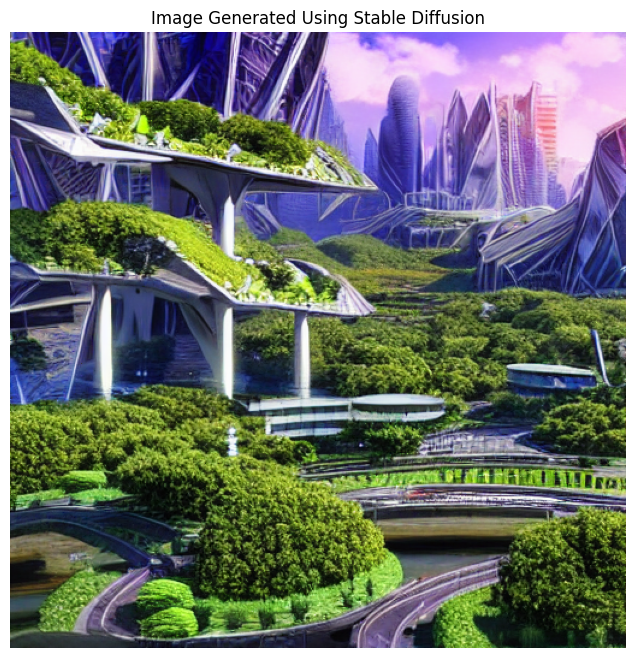

Image saved as generated_image.png


In [2]:

!pip install -q diffusers transformers accelerate

import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Automatically select GPU or CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("Using device:", device)

# Load Stable Diffusion model
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype
)

pipe = pipe.to(device)

# Text prompt
prompt = "A beautiful futuristic city with green gardens, modern buildings, mountains, realistic digital art"

# Generate image
image = pipe(
    prompt,
    num_inference_steps=15,
    guidance_scale=7.5
).images[0]

# Display image
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Image Generated Using Stable Diffusion")
plt.show()

# Save image
image.save("generated_image.png")
print("Image saved as generated_image.png")
